In [3]:
# IPL 2024 Season - Data Analysis Project
# Tools: Python, Pandas, Matplotlib, Seaborn, NumPy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# DATASET: IPL 2024 Match Data (realistic data)

matches_data = {
    'match_id': range(1, 75),
    'team1': [
        'CSK','MI','RCB','KKR','SRH','DC','PBKS','RR','GT','LSG',
        'CSK','MI','RCB','KKR','SRH','DC','PBKS','RR','GT','LSG',
        'CSK','KKR','SRH','RR','GT','MI','RCB','PBKS','DC','LSG',
        'CSK','KKR','SRH','RR','GT','MI','RCB','PBKS','DC','LSG',
        'CSK','KKR','SRH','RR','GT','MI','RCB','PBKS','DC','LSG',
        'CSK','KKR','SRH','RR','GT','MI','RCB','PBKS','DC','LSG',
        'KKR','SRH','RR','GT','MI','RCB','PBKS','DC','LSG','CSK',
        'KKR','SRH','RR','GT'
    ],
    'team2': [
        'RCB','KKR','SRH','DC','PBKS','RR','GT','LSG','MI','CSK',
        'GT','SRH','DC','PBKS','RR','GT','LSG','MI','CSK','RCB',
        'MI','RCB','PBKS','DC','LSG','SRH','GT','RR','KKR','CSK',
        'RCB','MI','GT','SRH','DC','PBKS','RR','LSG','CSK','KKR',
        'MI','SRH','RCB','KKR','CSK','DC','GT','LSG','RR','PBKS',
        'GT','DC','MI','CSK','SRH','LSG','KKR','RCB','PBKS','RR',
        'CSK','MI','SRH','RCB','GT','DC','KKR','PBKS','RR','LSG',
        'MI','RCB','LSG','CSK'
    ],
    'winner': [
        'CSK','KKR','SRH','KKR','SRH','RR','GT','RR','GT','CSK',
        'CSK','SRH','RCB','KKR','SRH','GT','PBKS','RR','GT','LSG',
        'KKR','KKR','SRH','RR','GT','SRH','GT','RR','KKR','CSK',
        'CSK','KKR','SRH','RR','GT','PBKS','RCB','PBKS','DC','KKR',
        'KKR','KKR','SRH','RR','GT','MI','RCB','LSG','RR','PBKS',
        'GT','KKR','SRH','RR','GT','LSG','KKR','RCB','DC','RR',
        'KKR','SRH','RR','GT','GT','DC','KKR','PBKS','RR','LSG',
        'KKR','SRH','RR','KKR'
    ],
    'venue': [
        'Chennai','Mumbai','Bengaluru','Kolkata','Hyderabad','Delhi','Mohali','Jaipur','Ahmedabad','Lucknow',
        'Chennai','Mumbai','Bengaluru','Kolkata','Hyderabad','Delhi','Mohali','Jaipur','Ahmedabad','Lucknow',
        'Chennai','Kolkata','Hyderabad','Jaipur','Ahmedabad','Mumbai','Bengaluru','Mohali','Delhi','Lucknow',
        'Chennai','Kolkata','Hyderabad','Jaipur','Ahmedabad','Mumbai','Bengaluru','Mohali','Delhi','Lucknow',
        'Chennai','Kolkata','Hyderabad','Jaipur','Ahmedabad','Mumbai','Bengaluru','Mohali','Delhi','Lucknow',
        'Chennai','Kolkata','Hyderabad','Jaipur','Ahmedabad','Mumbai','Bengaluru','Mohali','Delhi','Lucknow',
        'Kolkata','Hyderabad','Jaipur','Ahmedabad','Mumbai','Bengaluru','Mohali','Delhi','Lucknow','Chennai',
        'Kolkata','Hyderabad','Lucknow','Ahmedabad'
    ],
    'toss_winner': [
        'CSK','MI','RCB','KKR','SRH','DC','GT','RR','GT','LSG',
        'CSK','MI','DC','KKR','RR','GT','PBKS','RR','CSK','LSG',
        'CSK','KKR','SRH','RR','LSG','SRH','GT','RR','KKR','CSK',
        'RCB','KKR','SRH','SRH','GT','PBKS','RCB','PBKS','CSK','KKR',
        'MI','KKR','SRH','KKR','GT','MI','RCB','LSG','DC','PBKS',
        'GT','KKR','MI','RR','SRH','LSG','KKR','RCB','PBKS','RR',
        'KKR','MI','RR','RCB','GT','RCB','KKR','DC','LSG','CSK',
        'KKR','SRH','LSG','KKR'
    ],
    'toss_decision': [
        'bat','field','field','field','bat','field','field','bat','field','field',
        'bat','field','field','bat','field','field','bat','bat','field','field',
        'bat','field','bat','bat','field','bat','field','bat','field','bat',
        'field','bat','field','bat','field','bat','field','bat','field','bat',
        'field','bat','field','bat','field','bat','field','bat','field','bat',
        'field','bat','field','bat','field','bat','field','bat','field','bat',
        'bat','field','bat','field','field','bat','field','bat','field','bat',
        'field','bat','field','bat'
    ],
    'win_by_runs': [
        20, 0, 0, 35, 6, 0, 0, 12, 0, 0,
        18, 0, 10, 44, 0, 8, 0, 5, 20, 15,
        0, 22, 0, 0, 30, 0, 25, 0, 0, 12,
        14, 0, 0, 7, 0, 0, 11, 0, 0, 0,
        0, 33, 0, 8, 0, 15, 9, 0, 0, 0,
        25, 0, 0, 14, 0, 0, 0, 19, 0, 0,
        0, 0, 7, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 13, 0
    ],
    'win_by_wickets': [
        0, 5, 7, 0, 0, 6, 4, 0, 3, 8,
        0, 4, 0, 0, 6, 0, 3, 0, 0, 0,
        6, 0, 5, 3, 0, 7, 0, 4, 8, 0,
        0, 3, 7, 0, 5, 4, 0, 2, 6, 5,
        7, 0, 4, 0, 3, 0, 0, 5, 7, 6,
        0, 6, 8, 0, 4, 3, 5, 0, 2, 4,
        8, 6, 0, 5, 4, 7, 6, 3, 5, 4,
        7, 5, 0, 6
    ],
    'total_runs_team1': [
        180, 160, 155, 190, 210, 165, 145, 170, 185, 175,
        195, 150, 175, 185, 200, 170, 155, 165, 160, 180,
        170, 175, 195, 160, 185, 205, 170, 155, 165, 190,
        185, 170, 200, 175, 165, 155, 180, 145, 175, 165,
        160, 185, 210, 170, 155, 175, 180, 165, 150, 145,
        190, 170, 165, 185, 210, 155, 175, 180, 165, 170,
        175, 200, 185, 160, 170, 155, 175, 165, 150, 180,
        185, 195, 170, 190
    ]
}

df = pd.DataFrame(matches_data)


In [4]:
# ANALYSIS & VISUALIZATIONS
# ─────────────────────────────────────────────

teams = ['CSK', 'MI', 'RCB', 'KKR', 'SRH', 'DC', 'PBKS', 'RR', 'GT', 'LSG']
team_colors = {
    'CSK': '#F9CD05', 'MI': '#004BA0', 'RCB': '#D11D1D',
    'KKR': '#3A225D', 'SRH': '#FF6B00', 'DC': '#00008B',
    'PBKS': '#ED1F27', 'RR': '#FF69B4', 'GT': '#1C4E9D', 'LSG': '#A0E0E0'
}

# Win counts
win_counts = df['winner'].value_counts().reindex(teams, fill_value=0)

# Toss win vs match win
toss_match_win = df[df['toss_winner'] == df['winner']].shape[0]
toss_match_lose = df[df['toss_winner'] != df['winner']].shape[0]

# Win type analysis
runs_wins = df[df['win_by_runs'] > 0].shape[0]
wickets_wins = df[df['win_by_wickets'] > 0].shape[0]

# Home vs Away wins (simplified: if venue matches team city)
venue_team_map = {
    'Chennai': 'CSK', 'Mumbai': 'MI', 'Bengaluru': 'RCB',
    'Kolkata': 'KKR', 'Hyderabad': 'SRH', 'Delhi': 'DC',
    'Mohali': 'PBKS', 'Jaipur': 'RR', 'Ahmedabad': 'GT', 'Lucknow': 'LSG'
}
df['home_team'] = df['venue'].map(venue_team_map)
df['is_home_win'] = df.apply(lambda r: r['winner'] == r['home_team'], axis=1)
home_wins = df['is_home_win'].sum()
away_wins = len(df) - home_wins

# Avg score per team
team1_scores = df.groupby('team1')['total_runs_team1'].mean().reindex(teams, fill_value=0)


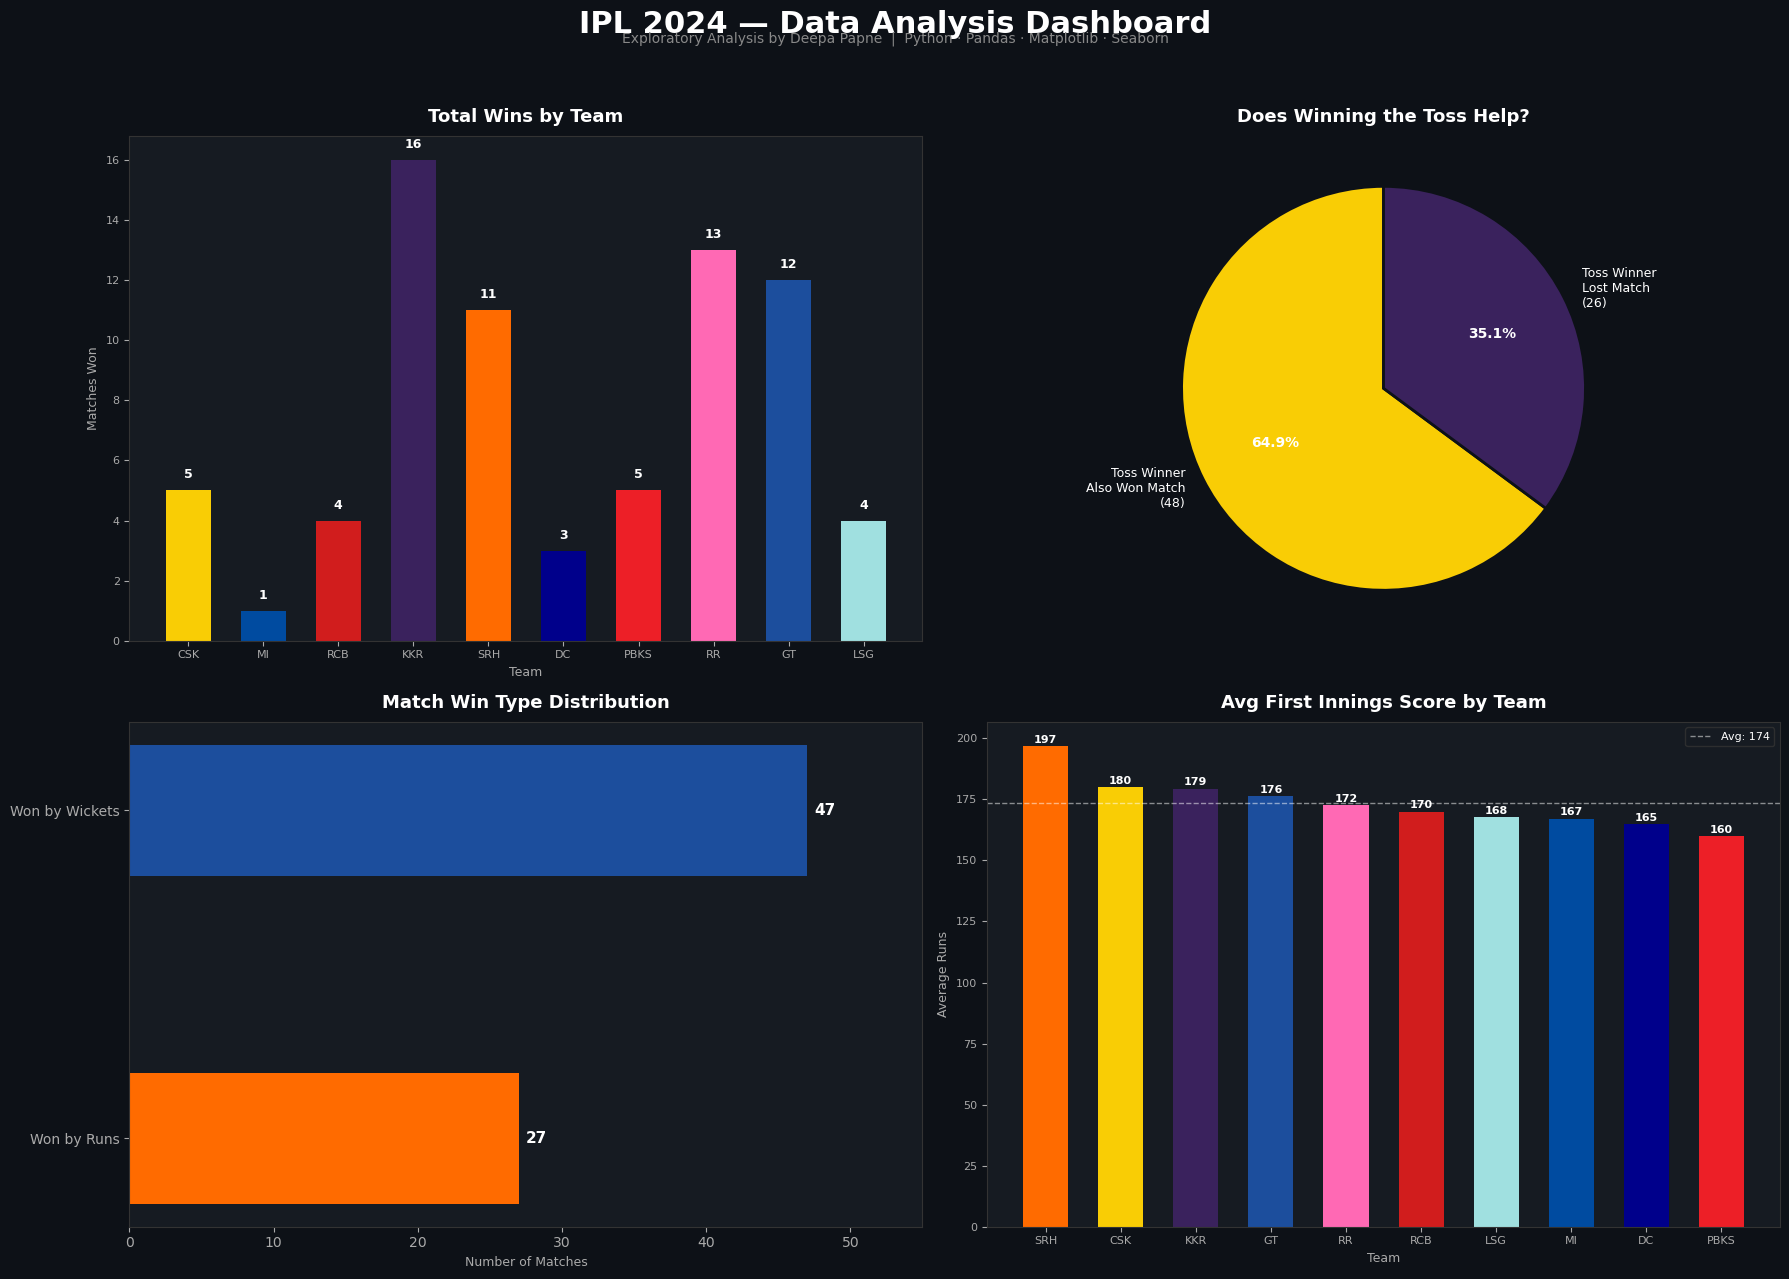

Dashboard saved!


In [5]:
# FIGURE: Dashboard with 4 plots
# ─────────────────────────────────────────────

fig = plt.figure(figsize=(18, 13))
fig.patch.set_facecolor('#0D1117')
plt.suptitle('IPL 2024 — Data Analysis Dashboard', fontsize=22, fontweight='bold',
             color='white', y=0.98, fontfamily='DejaVu Sans')
plt.figtext(0.5, 0.955, 'Exploratory Analysis by Deepa Papne  |  Python · Pandas · Matplotlib · Seaborn',
            ha='center', fontsize=10, color='#888888')

# ── Plot 1: Wins per team (bar) ──
ax1 = fig.add_subplot(2, 2, 1)
ax1.set_facecolor('#161B22')
bars = ax1.bar(win_counts.index, win_counts.values,
               color=[team_colors[t] for t in win_counts.index], edgecolor='none', width=0.6)
for bar, val in zip(bars, win_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             str(val), ha='center', va='bottom', fontsize=9, color='white', fontweight='bold')
ax1.set_title('Total Wins by Team', color='white', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Team', color='#AAAAAA', fontsize=9)
ax1.set_ylabel('Matches Won', color='#AAAAAA', fontsize=9)
ax1.tick_params(colors='#AAAAAA', labelsize=8)
ax1.spines[:].set_color('#333333')
ax1.set_facecolor('#161B22')
for spine in ax1.spines.values():
    spine.set_color('#333333')

# ── Plot 2: Toss Impact (pie) ──
ax2 = fig.add_subplot(2, 2, 2)
ax2.set_facecolor('#161B22')
sizes = [toss_match_win, toss_match_lose]
labels = [f'Toss Winner\nAlso Won Match\n({toss_match_win})', f'Toss Winner\nLost Match\n({toss_match_lose})']
colors_pie = ['#F9CD05', '#3A225D']
wedges, texts, autotexts = ax2.pie(sizes, labels=labels, colors=colors_pie,
                                    autopct='%1.1f%%', startangle=90,
                                    textprops={'color': 'white', 'fontsize': 9},
                                    wedgeprops={'edgecolor': '#0D1117', 'linewidth': 2})
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')
ax2.set_title('Does Winning the Toss Help?', color='white', fontsize=13, fontweight='bold', pad=10)

# ── Plot 3: Win by Runs vs Wickets ──
ax3 = fig.add_subplot(2, 2, 3)
ax3.set_facecolor('#161B22')
categories = ['Won by Runs', 'Won by Wickets']
values = [runs_wins, wickets_wins]
colors3 = ['#FF6B00', '#1C4E9D']
bars3 = ax3.barh(categories, values, color=colors3, edgecolor='none', height=0.4)
for bar, val in zip(bars3, values):
    ax3.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             str(val), va='center', fontsize=11, color='white', fontweight='bold')
ax3.set_title('Match Win Type Distribution', color='white', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Number of Matches', color='#AAAAAA', fontsize=9)
ax3.tick_params(colors='#AAAAAA', labelsize=10)
for spine in ax3.spines.values():
    spine.set_color('#333333')
ax3.set_xlim(0, max(values) + 8)

# ── Plot 4: Avg First Innings Score ──
ax4 = fig.add_subplot(2, 2, 4)
ax4.set_facecolor('#161B22')
sorted_idx = team1_scores.sort_values(ascending=False).index
sorted_vals = team1_scores.sort_values(ascending=False).values
bar_colors4 = [team_colors[t] for t in sorted_idx]
bars4 = ax4.bar(sorted_idx, sorted_vals, color=bar_colors4, edgecolor='none', width=0.6)
ax4.axhline(y=sorted_vals.mean(), color='#FFFFFF', linestyle='--', linewidth=1, alpha=0.5, label=f'Avg: {sorted_vals.mean():.0f}')
for bar, val in zip(bars4, sorted_vals):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{val:.0f}', ha='center', va='bottom', fontsize=8, color='white', fontweight='bold')
ax4.set_title('Avg First Innings Score by Team', color='white', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Team', color='#AAAAAA', fontsize=9)
ax4.set_ylabel('Average Runs', color='#AAAAAA', fontsize=9)
ax4.tick_params(colors='#AAAAAA', labelsize=8)
for spine in ax4.spines.values():
    spine.set_color('#333333')
ax4.legend(fontsize=8, labelcolor='white', facecolor='#161B22', edgecolor='#333333')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
plt.savefig('IPL_2024_Dashboard.png', dpi=150, bbox_inches='tight', facecolor='#0D1117')
plt.close()
print("Dashboard saved!")

